# Frag Gen Comparison

Compare three NIST23 d3 fragmentation generation configs:

| Config | `multi_cut_bfs` | `max_cut_size` | `smarts_prepass` | `min_frag_atoms` |
|--------|----------------|----------------|-----------------|------------------|
| **baseline** (`_isoFalse`) | False | — | — | — |
| **mbfs** (`_isoFalse_mbfs`) | True | 2 | False | 3 |
| **mbfs_prepass** (`_isoFalse_mbfs_prepass`) | True | 2 | True | — |

In [11]:
import io
import json
import pickle
import tarfile
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

FRAG_DP = Path("../data/frag")

CONFIGS = {
    "baseline": FRAG_DP / "nist23_ma_mi_d3_h4_isoFalse",
    "mbfs": FRAG_DP / "nist23_ma_mi_d3_h4_isoFalse_mbfs.tar",
    "mbfs_prepass": FRAG_DP / "nist23_ma_mi_d3_h4_isoFalse_mbfs_prepass",
}

DF_NAMES = ["spec_stats_df", "mol_stats_df", "m_spec_stats_df", "m_mol_stats_df"]

In [12]:
def load_dfs(path: Path) -> dict[str, pd.DataFrame]:
    """Load all stats pkl files from a directory or a .tar archive."""
    dfs = {}
    if path.suffix == ".tar":
        with tarfile.open(path) as tf:
            members = {Path(m.name).name: m for m in tf.getmembers() if m.name.endswith(".pkl")}
            for name in DF_NAMES:
                fname = f"{name}.pkl"
                if fname in members:
                    f = tf.extractfile(members[fname])
                    dfs[name] = pd.read_pickle(io.BytesIO(f.read()))
        # also load global_stats.json from tar
        with tarfile.open(path) as tf:
            for m in tf.getmembers():
                if m.name.endswith("global_stats.json"):
                    f = tf.extractfile(m)
                    dfs["global_stats"] = json.load(f)
    else:
        for name in DF_NAMES:
            pkl_path = path / f"{name}.pkl"
            if pkl_path.exists():
                dfs[name] = pd.read_pickle(pkl_path)
        gs_path = path / "global_stats.json"
        if gs_path.exists():
            dfs["global_stats"] = json.loads(gs_path.read_text())
    return dfs


all_dfs = {name: load_dfs(path) for name, path in CONFIGS.items()}

for cfg, dfs in all_dfs.items():
    print(f"{cfg}: loaded {list(dfs.keys())}")
    for k, v in dfs.items():
        if isinstance(v, pd.DataFrame):
            print(f"  {k}: {v.shape}")

baseline: loaded ['spec_stats_df', 'mol_stats_df', 'm_spec_stats_df', 'm_mol_stats_df', 'global_stats']
  spec_stats_df: (805040, 177)
  mol_stats_df: (43414, 176)
  m_spec_stats_df: (127090, 177)
  m_mol_stats_df: (43414, 176)
mbfs: loaded ['spec_stats_df', 'mol_stats_df', 'm_spec_stats_df', 'm_mol_stats_df', 'global_stats']
  spec_stats_df: (804966, 177)
  mol_stats_df: (43407, 176)
  m_spec_stats_df: (127068, 177)
  m_mol_stats_df: (43407, 176)
mbfs_prepass: loaded ['spec_stats_df', 'mol_stats_df', 'm_spec_stats_df', 'm_mol_stats_df', 'global_stats']
  spec_stats_df: (804966, 177)
  mol_stats_df: (43407, 176)
  m_spec_stats_df: (127068, 177)
  m_mol_stats_df: (43407, 176)


## Global Stats

In [13]:
GS_KEYS = [
    "total_num_failures",
    "total_num_formulae",
    "dag_num_nodes/mean",
    "dag_num_nodes/50%",
    "dag_num_edges/mean",
    "dag_num_edges/50%",
    "num_formulae/mean",
    "num_formulae/50%",
    "formula_redundancy/mean",
    "formula_redundancy/50%",
    "spec/recall_0.01_h2/mean",
    "spec/wrecall_0.01_h2/mean",
    "spec/wrecall_0.01_h2/50%",
    "spec/prec_0.01_h2/mean",
    "spec/recall_0.01_h2/50%",
]

rows = []
for cfg, dfs in all_dfs.items():
    gs = dfs.get("global_stats", {})
    row = {"config": cfg}
    for k in GS_KEYS:
        row[k] = gs.get(k, float("nan"))
    rows.append(row)

gs_df = pd.DataFrame(rows).set_index("config").T
gs_df

config,baseline,mbfs,mbfs_prepass
total_num_failures,0,7,7
total_num_formulae,1162724,1531391,1628440
dag_num_nodes/mean,693.3267379186437,1386.318957771788,1676.0804248162738
dag_num_nodes/50%,304.0,387.0,413.0
dag_num_edges/mean,3750.418897129958,3359.2730204805675,4665.819614347916
dag_num_edges/50%,1226.0,874.0,946.0
num_formulae/mean,823.0022573363431,1182.0555209989172,1266.2317828921603
num_formulae/50%,549.0,651.0,676.0
formula_redundancy/mean,4.377786780409257,5.437873433522641,5.781945949389275
formula_redundancy/50%,3.4173506123851967,3.562618595825427,3.6504504504504505


## Spec-level Stats: recall & wrecall at 0.01 Da, h1–h4

In [14]:
# Focus on standard tolerance 0.01 Da
TOL = "0.01"
H_LEVELS = [1, 2, 3, 4]
METRICS = ["recall", "wrecall", "prec", "ppt_peak", "ppt_formula"]

summary_rows = []
for cfg, dfs in all_dfs.items():
    spec_df = dfs.get("spec_stats_df")
    if spec_df is None:
        continue
    row = {"config": cfg}
    for h in H_LEVELS:
        for metric in METRICS:
            col = f"{metric}_{TOL}_h{h}"
            if col in spec_df.columns:
                row[f"{metric}_h{h}_mean"] = spec_df[col].mean()
                row[f"{metric}_h{h}_median"] = spec_df[col].median()
    # DAG stats
    for col in ["num_formulae", "dag_num_nodes", "dag_num_edges", "formula_redundancy"]:
        if col in spec_df.columns:
            row[f"{col}_mean"] = spec_df[col].mean()
            row[f"{col}_median"] = spec_df[col].median()
    summary_rows.append(row)

summary_df = pd.DataFrame(summary_rows).set_index("config")

# Show recall/wrecall
recall_cols = [c for c in summary_df.columns if c.startswith(("recall", "wrecall"))]
print("=== Recall & wrecall (mean) ===")
display(summary_df[[c for c in recall_cols if "mean" in c]].T)

print("\n=== DAG stats ===")
dag_cols = [c for c in summary_df.columns if any(c.startswith(x) for x in ["num_formulae", "dag_num_nodes", "dag_num_edges", "formula_redundancy"])]
display(summary_df[dag_cols].T)

=== Recall & wrecall (mean) ===


config,baseline,mbfs,mbfs_prepass
recall_h1_mean,0.322657,0.386330,0.404931
wrecall_h1_mean,0.431174,0.509982,0.526947
recall_h2_mean,0.626252,0.632785,0.649304
wrecall_h2_mean,0.779909,0.768712,0.781000
recall_h3_mean,0.716339,0.718051,0.733312
wrecall_h3_mean,0.843857,0.831612,0.842739
recall_h4_mean,0.757700,0.754529,0.768296
wrecall_h4_mean,0.871635,0.855747,0.866035



=== DAG stats ===


config,baseline,mbfs,mbfs_prepass
num_formulae_mean,898.363735,1312.125862,1409.347462
num_formulae_median,618.000000,763.000000,798.000000
dag_num_nodes_mean,779.030724,1544.570932,1863.179226
dag_num_nodes_median,341.000000,462.000000,493.000000
dag_num_edges_mean,4173.773723,3743.621030,5143.046705
dag_num_edges_median,1422.000000,1041.000000,1131.000000
formula_redundancy_mean,4.666787,5.710245,6.083445
formula_redundancy_median,3.527304,3.732425,3.826812


## Distribution plots: wrecall & recall at 0.01 Da, h2

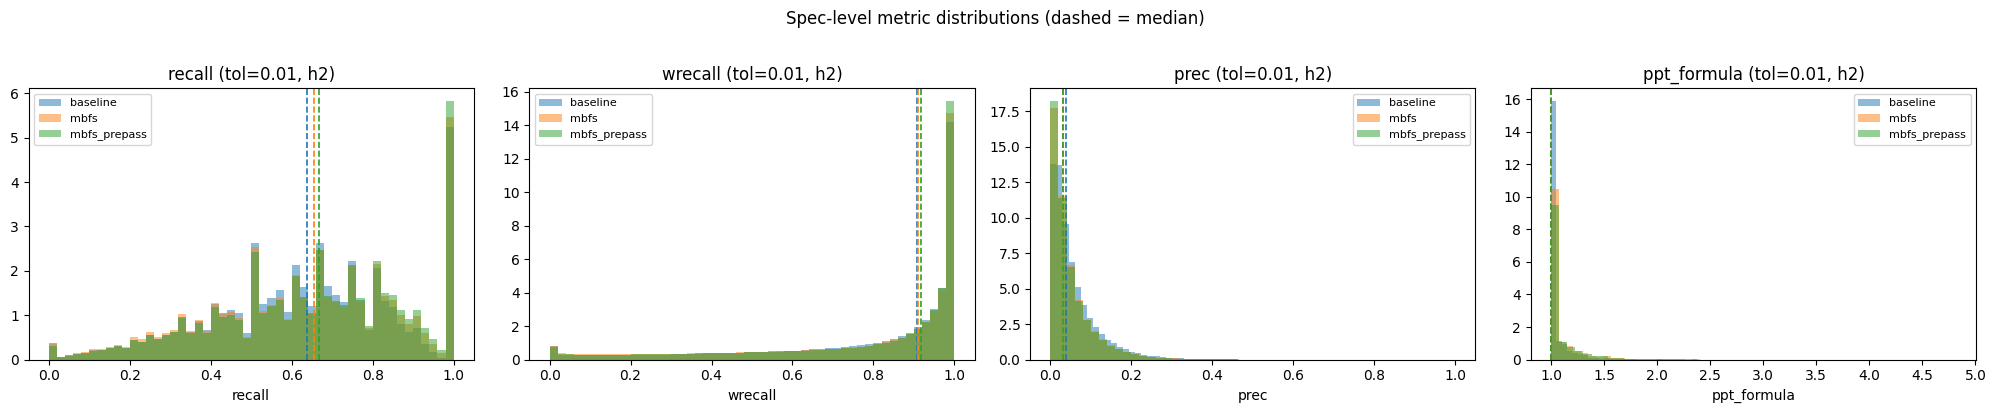

In [15]:
COLORS = {"baseline": "tab:blue", "mbfs": "tab:orange", "mbfs_prepass": "tab:green"}
H = 2
PLOT_METRICS = ["recall", "wrecall", "prec", "ppt_formula"]

fig, axes = plt.subplots(1, len(PLOT_METRICS), figsize=(5 * len(PLOT_METRICS), 4))

for ax, metric in zip(axes, PLOT_METRICS):
    col = f"{metric}_{TOL}_h{H}"
    for cfg, dfs in all_dfs.items():
        spec_df = dfs.get("spec_stats_df")
        if spec_df is None or col not in spec_df.columns:
            continue
        vals = spec_df[col].dropna()
        ax.hist(vals, bins=50, alpha=0.5, label=cfg, color=COLORS[cfg], density=True)
        ax.axvline(vals.median(), linestyle="--", color=COLORS[cfg], linewidth=1.2)
    ax.set_title(f"{metric} (tol={TOL}, h{H})")
    ax.set_xlabel(metric)
    ax.legend(fontsize=8)

plt.suptitle("Spec-level metric distributions (dashed = median)", y=1.02)
plt.tight_layout()
plt.show()

## wrecall across h-levels (median)

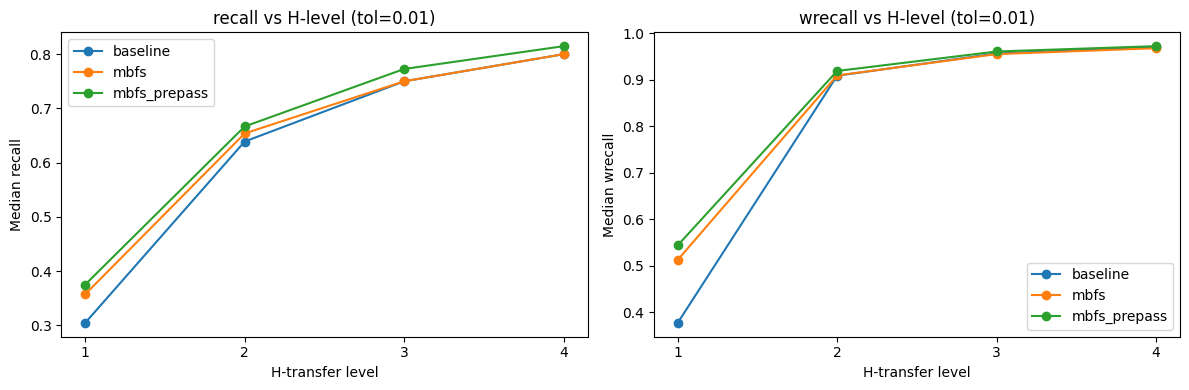

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for ax, metric in zip(axes, ["recall", "wrecall"]):
    for cfg, dfs in all_dfs.items():
        spec_df = dfs.get("spec_stats_df")
        if spec_df is None:
            continue
        medians = []
        for h in H_LEVELS:
            col = f"{metric}_{TOL}_h{h}"
            if col in spec_df.columns:
                medians.append(spec_df[col].median())
            else:
                medians.append(np.nan)
        ax.plot(H_LEVELS, medians, marker="o", label=cfg, color=COLORS[cfg])
    ax.set_xlabel("H-transfer level")
    ax.set_ylabel(f"Median {metric}")
    ax.set_title(f"{metric} vs H-level (tol={TOL})")
    ax.legend()
    ax.set_xticks(H_LEVELS)

plt.tight_layout()
plt.show()

## num_formulae & dag_num_nodes distributions

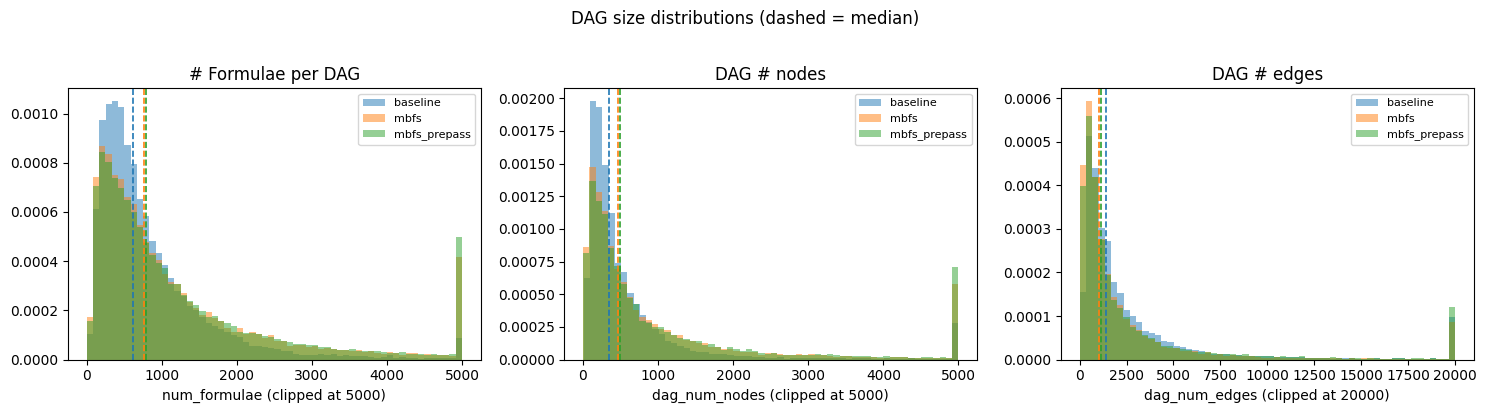

In [17]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, (col, label, clip) in zip(
    axes,
    [
        ("num_formulae", "# Formulae per DAG", 5000),
        ("dag_num_nodes", "DAG # nodes", 5000),
        ("dag_num_edges", "DAG # edges", 20000),
    ],
):
    for cfg, dfs in all_dfs.items():
        spec_df = dfs.get("spec_stats_df")
        if spec_df is None or col not in spec_df.columns:
            continue
        vals = spec_df[col].clip(upper=clip).dropna()
        ax.hist(vals, bins=60, alpha=0.5, label=cfg, color=COLORS[cfg], density=True)
        ax.axvline(spec_df[col].median(), linestyle="--", color=COLORS[cfg], linewidth=1.2)
    ax.set_title(label)
    ax.set_xlabel(f"{col} (clipped at {clip})")
    ax.legend(fontsize=8)

plt.suptitle("DAG size distributions (dashed = median)", y=1.02)
plt.tight_layout()
plt.show()

## Mol-level: median wrecall & recall (m_mol_stats_df)

In [18]:
mol_rows = []
for cfg, dfs in all_dfs.items():
    mol_df = dfs.get("m_mol_stats_df")
    if mol_df is None:
        mol_df = dfs.get("mol_stats_df")
    if mol_df is None:
        continue
    row = {"config": cfg, "n_mols": len(mol_df)}
    for h in H_LEVELS:
        for metric in ["recall", "wrecall", "prec"]:
            col = f"{metric}_{TOL}_h{h}"
            if col in mol_df.columns:
                row[f"{metric}_h{h}_median"] = mol_df[col].median()
                row[f"{metric}_h{h}_mean"] = mol_df[col].mean()
    mol_rows.append(row)

mol_summary = pd.DataFrame(mol_rows).set_index("config")
display(mol_summary.T)

config,baseline,mbfs,mbfs_prepass
n_mols,43414.000000,43407.000000,43407.000000
recall_h1_median,0.291133,0.354570,0.369767
recall_h1_mean,0.300311,0.364819,0.382161
wrecall_h1_median,0.333116,0.473906,0.497445
wrecall_h1_mean,0.378894,0.470580,0.487893
prec_h1_median,0.076577,0.064767,0.064488
prec_h1_mean,0.098019,0.088304,0.087854
recall_h2_median,0.618458,0.638514,0.654070
recall_h2_mean,0.609619,0.620821,0.634819
wrecall_h2_median,0.846706,0.838274,0.848604


## Direct diff: mbfs vs baseline & mbfs_prepass vs mbfs (spec-level, h2, 0.01 Da)

In [19]:
# Join on spec_id to compare directly
H = 2
COMPARE_COLS = [f"{m}_{TOL}_h{H}" for m in ["recall", "wrecall", "prec", "ppt_formula"]]

baseline_df = all_dfs["baseline"]["spec_stats_df"].set_index("spec_id")[COMPARE_COLS]
mbfs_df = all_dfs["mbfs"]["spec_stats_df"].set_index("spec_id")[COMPARE_COLS]
prepass_df = all_dfs["mbfs_prepass"]["spec_stats_df"].set_index("spec_id")[COMPARE_COLS]

common_base_mbfs = baseline_df.index.intersection(mbfs_df.index)
common_mbfs_pp = mbfs_df.index.intersection(prepass_df.index)

diff_mbfs_vs_base = mbfs_df.loc[common_base_mbfs] - baseline_df.loc[common_base_mbfs]
diff_pp_vs_mbfs = prepass_df.loc[common_mbfs_pp] - mbfs_df.loc[common_mbfs_pp]

print(f"Specs in common (mbfs vs baseline): {len(common_base_mbfs)}")
print(f"Specs in common (prepass vs mbfs):   {len(common_mbfs_pp)}")

print("\n=== mbfs - baseline (mean delta) ===")
display(diff_mbfs_vs_base.mean().to_frame("mean_delta").T)

print("\n=== mbfs_prepass - mbfs (mean delta) ===")
display(diff_pp_vs_mbfs.mean().to_frame("mean_delta").T)

Specs in common (mbfs vs baseline): 804966
Specs in common (prepass vs mbfs):   804966

=== mbfs - baseline (mean delta) ===


,recall_0.01_h2,wrecall_0.01_h2,prec_0.01_h2,ppt_formula_0.01_h2
mean_delta,0.006548,-0.011194,-0.008047,0.038889



=== mbfs_prepass - mbfs (mean delta) ===


,recall_0.01_h2,wrecall_0.01_h2,prec_0.01_h2,ppt_formula_0.01_h2
mean_delta,0.016519,0.012288,-0.000724,0.007028


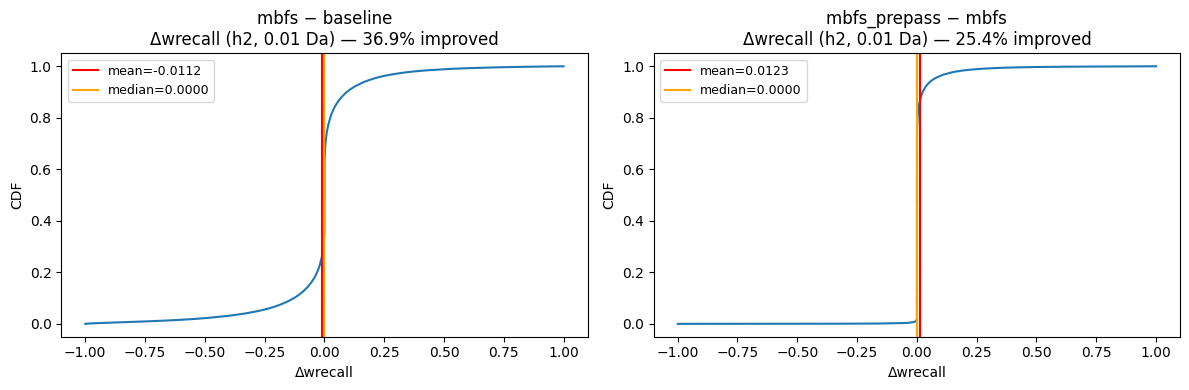

In [20]:
# CDF of wrecall delta
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
wcol = f"wrecall_{TOL}_h{H}"

for ax, (diff, title) in zip(
    axes,
    [
        (diff_mbfs_vs_base[wcol], "mbfs − baseline"),
        (diff_pp_vs_mbfs[wcol], "mbfs_prepass − mbfs"),
    ],
):
    vals = diff.sort_values()
    cdf = np.arange(1, len(vals) + 1) / len(vals)
    ax.plot(vals, cdf)
    ax.axvline(0, color="gray", linestyle="--")
    ax.axvline(vals.mean(), color="red", linestyle="-", label=f"mean={vals.mean():.4f}")
    ax.axvline(vals.median(), color="orange", linestyle="-", label=f"median={vals.median():.4f}")
    frac_pos = (vals > 0).mean()
    ax.set_title(f"{title}\nΔwrecall (h{H}, {TOL} Da) — {frac_pos:.1%} improved")
    ax.set_xlabel("Δwrecall")
    ax.set_ylabel("CDF")
    ax.legend(fontsize=9)

plt.tight_layout()
plt.show()